<a href="https://colab.research.google.com/github/Muskaan555/rna-seq-transcriptome-bioinformatics-project/blob/main/Gene_expression_analysis_using_python_tools.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Analysing a FASTA file in Biopython**

Reading a FASTA file

In [2]:
#install biopython
! pip install biopython

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 76.2 MB/s eta 0:00:00


Getting file information, seqID, calcultaing seqID, Seq length, nucleotide composition, GC and AT%

In [7]:
from Bio import SeqIO
from collections import Counter
for seq_record in SeqIO.parse("gene.fna", "fasta"):
  counts = Counter(seq_record)
  length = len(seq_record)
  gc_percent = (counts["G"] + counts["C"]) / length * 100 if length else 0
  at_percent = (counts["A"] + counts["T"]) / length * 100 if length else 0
  print(seq_record.id)
  print(repr(seq_record.seq))
  print(len(seq_record))
  print("ID:", seq_record.id)
  print("Length:", len(seq_record))
  print("Sequence:", seq_record.seq)
  print("Description:", seq_record.description)
  print("Nucleotide composition:", {
        base: counts[base] for base in "ACGTN"
    })
  print("GC content:", gc_percent)
  print("AT content:", at_percent)

NC_000017.11:c7687490-7668421
Seq('CTCAAAAGTCTAGAGCCACCGTCCAGGGAGCAGGTAGCTGCTGGGCTCCGGGGA...CCA')
19070
ID: NC_000017.11:c7687490-7668421
Length: 19070
Sequence: CTCAAAAGTCTAGAGCCACCGTCCAGGGAGCAGGTAGCTGCTGGGCTCCGGGGACACTTTGCGTTCGGGCTGGGAGCGTGCTTTCCACGACGGTGACACGCTTCCCTGGATTGGGTAAGCTCCTGACTGAACTTGATGAGTCCTCTCTGAGTCACGGGCTCTCGGCTCCGTGTATTTTCAGCTCGGGAAAATCGCTGGGGCTGGGGGTGGGGCAGTGGGGACTTAGCGAGTTTGGGGGTGAGTGGGATGGAAGCTTGGCTAGAGGGATCATCATAGGAGTTGCATTGTTGGGAGACCTGGGTGTAGATGATGGGGATGTTAGGACCATCCGAACTCAAAGTTGAACGCCTAGGCAGAGGAGTGGAGCTTTGGGGAACCTTGAGCCGGCCTAAAGCGTACTTCTTTGCACATCCACCCGGTGCTGGGCGTAGGGAATCCCTGAAATAAAAGATGCACAAAGCATTGAGGTCTGAGACTTTTGGATCTCGAAACATTGAGAACTCATAGCTGTATATTTTAGAGCCCATGGCATCCTAGTGAAAACTGGGGCTCCATTCCGAAATGATCATTTGGGGGTGATCCGGGGAGCCCAAGCTGCTAAGGTCCCACAACTTCCGGACCTTTGTCCTTCCTGGAGCGATCTTTCCAGGCAGCCCCCGGCTCCGCTAGATGGAGAAAATCCAATTGAAGGCTGTCAGTCGTGGAAGTGAGAAGTGCTAAACCAGGGGTTTGCCCGCCAGGCCGAGGAGGACCGTCGCAATCTGAGAGGCCCGGCAGCCCTGTTATTGTTTGGCTCCACATTTACATTTCTGCCTCTTGCAGCAGCATTTCCGGTTTC

 Sequence validation

In [9]:
valid_bases = set("ACGTN")

for record in SeqIO.parse("gene.fna", "fasta"):
    unexpected = sorted(set(seq_record) - valid_bases)

if unexpected:
        print(seq_record.id, "Invalid characters:", unexpected)
else:
        print(seq_record.id, "Valid DNA sequence")

NC_060941.1:c7591594-7572544 Valid DNA sequence


**Analysing a CSV file in Python **

Reading a CSV file 1

In [10]:
import pandas as pd

df = pd.read_csv("GSE42568_sample_metadata.csv")
print(df)

         Sample                 Sample_Title Condition
0    GSM1045191   Normal breast, N1_15_12_04    Normal
1    GSM1045192   Normal breast, N4_14_12_04    Normal
2    GSM1045193   Normal breast, N5_15_12_04    Normal
3    GSM1045194   Normal breast, N6_14_12_04    Normal
4    GSM1045195   Normal breast, P1_15_12_04    Normal
..          ...                          ...       ...
116  GSM1045307   Breast cancer, T94_9_12_04    Cancer
117  GSM1045308   Breast cancer, T97_3_12_04    Cancer
118  GSM1045309  Breast cancer, T98_22_12_04    Cancer
119  GSM1045310  Breast cancer, T99_20_12_04    Cancer
120  GSM1045311   Breast cancer, T9A_9_12_04    Cancer

[121 rows x 3 columns]


In [13]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 121 entries, 0 to 120
Data columns (total 3 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   Sample        121 non-null    object
 1   Sample_Title  121 non-null    object
 2   Condition     121 non-null    object
dtypes: object(3)
memory usage: 3.0+ KB


In [14]:
df.head()

,Sample,Sample_Title,Condition
0,GSM1045191,"Normal breast, N1_15_12_04",Normal
1,GSM1045192,"Normal breast, N4_14_12_04",Normal
2,GSM1045193,"Normal breast, N5_15_12_04",Normal
3,GSM1045194,"Normal breast, N6_14_12_04",Normal
4,GSM1045195,"Normal breast, P1_15_12_04",Normal


In [15]:
df.tail()

,Sample,Sample_Title,Condition
116,GSM1045307,"Breast cancer, T94_9_12_04",Cancer
117,GSM1045308,"Breast cancer, T97_3_12_04",Cancer
118,GSM1045309,"Breast cancer, T98_22_12_04",Cancer
119,GSM1045310,"Breast cancer, T99_20_12_04",Cancer
120,GSM1045311,"Breast cancer, T9A_9_12_04",Cancer


In [16]:
df.shape

(121, 3)

In [17]:
df.columns

Index(['Sample', 'Sample_Title', 'Condition'], dtype='object')

In [18]:
df[["Sample_Title", "Condition"]]

,Sample_Title,Condition
0,"Normal breast, N1_15_12_04",Normal
1,"Normal breast, N4_14_12_04",Normal
2,"Normal breast, N5_15_12_04",Normal
3,"Normal breast, N6_14_12_04",Normal
4,"Normal breast, P1_15_12_04",Normal
...,...,...
116,"Breast cancer, T94_9_12_04",Cancer
117,"Breast cancer, T97_3_12_04",Cancer
118,"Breast cancer, T98_22_12_04",Cancer
119,"Breast cancer, T99_20_12_04",Cancer


Missing values

In [19]:
df.isna()

,Sample,Sample_Title,Condition
0,False,False,False
1,False,False,False
2,False,False,False
3,False,False,False
4,False,False,False
...,...,...,...
116,False,False,False
117,False,False,False
118,False,False,False
119,False,False,False


In [20]:
df.isna().sum()

,0
Sample,0
Sample_Title,0
Condition,0


In [23]:
df.duplicated()

,0
0,False
1,False
2,False
3,False
4,False
...,...
116,False
117,False
118,False
119,False


In [24]:
df.duplicated().sum()

np.int64(0)

In [30]:
print(df.columns.tolist())


['Sample', 'Sample_Title', 'Condition']


In [31]:
control = df[df["Condition"].str.lower() == "normal"]

In [32]:
print(control)

        Sample                Sample_Title Condition
0   GSM1045191  Normal breast, N1_15_12_04    Normal
1   GSM1045192  Normal breast, N4_14_12_04    Normal
2   GSM1045193  Normal breast, N5_15_12_04    Normal
3   GSM1045194  Normal breast, N6_14_12_04    Normal
4   GSM1045195  Normal breast, P1_15_12_04    Normal
5   GSM1045196  Normal breast, P10_26_1_05    Normal
6   GSM1045197  Normal breast, P11_25_1_05    Normal
7   GSM1045198  Normal breast, P12_25_1_05    Normal
8   GSM1045199  Normal breast, P13_25_1_05    Normal
9   GSM1045200  Normal breast, P14_25_1_05    Normal
10  GSM1045201  Normal breast, P18_25_1_05    Normal
11  GSM1045202  Normal breast, P21_25_1_05    Normal
12  GSM1045203  Normal breast, P3_22_12_04    Normal
13  GSM1045204  Normal breast, P4_14_12_04    Normal
14  GSM1045205  Normal breast, P5_21_12_04    Normal
15  GSM1045206   Normal breast, P8_25_1_05    Normal
16  GSM1045207   Normal breast, P9_25_1_05    Normal


In [37]:
disease = df[df["Condition"].str.lower() == "cancer"]

In [38]:
print(disease)

         Sample                 Sample_Title Condition
17   GSM1045208   Breast cancer, S1_21_12_04    Cancer
18   GSM1045209  Breast cancer, S10_22_12_04    Cancer
19   GSM1045210  Breast cancer, S11_14_12_04    Cancer
20   GSM1045211  Breast cancer, S14_21_12_04    Cancer
21   GSM1045212  Breast cancer, S15_15_12_04    Cancer
..          ...                          ...       ...
116  GSM1045307   Breast cancer, T94_9_12_04    Cancer
117  GSM1045308   Breast cancer, T97_3_12_04    Cancer
118  GSM1045309  Breast cancer, T98_22_12_04    Cancer
119  GSM1045310  Breast cancer, T99_20_12_04    Cancer
120  GSM1045311   Breast cancer, T9A_9_12_04    Cancer

[104 rows x 3 columns]


In [39]:
import pandas as pd
import matplotlib.pyplot as plt

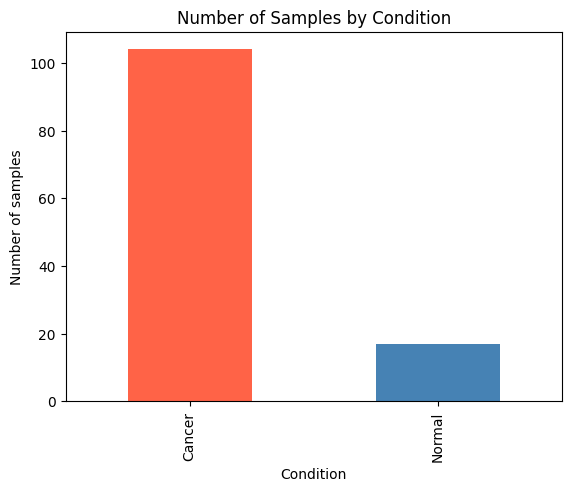

In [40]:
df = pd.read_csv("GSE42568_sample_metadata.csv")

df["Condition"].value_counts().plot(kind="bar", color=["tomato", "steelblue"])
plt.title("Number of Samples by Condition")
plt.xlabel("Condition")
plt.ylabel("Number of samples")
plt.show()

In [2]:
import pandas as pd

In [3]:
expression = pd.read_csv("GSE42568_gene_symbol_expression_matrix.csv")
print(expression)

      Gene_Symbol  GSM1045191  GSM1045192  GSM1045193  GSM1045194  GSM1045195  \
0            A1BG    3.403199    4.037233    3.860598    3.937074    3.937074   
1        A1BG-AS1    4.045971    4.219688    4.280795    4.066748    4.066748   
2            A1CF    2.319143    2.320107    3.449948    2.376034    2.320107   
3             A2M    6.435412    6.423260    3.687021    6.384210    6.557870   
4         A2M-AS1    4.355747    3.154174    2.751123    2.775390    4.385987   
...           ...         ...         ...         ...         ...         ...   
21750      ZYG11A    2.706529    2.970567    2.970567    2.976640    2.463669   
21751      ZYG11B    6.922288    5.354092    4.258431    5.167245    6.967129   
21752         ZYX    4.931123    5.914508    4.638179    4.701639    5.731091   
21753       ZZEF1    4.235765    3.777136    3.623103    3.435938    4.263578   
21754        ZZZ3    6.046628    5.358335    6.095821    5.063904    5.581506   

       GSM1045196  GSM10451

In [4]:
expression.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21755 entries, 0 to 21754
Columns: 122 entries, Gene_Symbol to GSM1045311
dtypes: float64(121), object(1)
memory usage: 20.2+ MB


In [5]:
expression.head()

,Gene_Symbol,GSM1045191,GSM1045192,GSM1045193,GSM1045194,GSM1045195,GSM1045196,GSM1045197,GSM1045198,GSM1045199,...,GSM1045302,GSM1045303,GSM1045304,GSM1045305,GSM1045306,GSM1045307,GSM1045308,GSM1045309,GSM1045310,GSM1045311
0,A1BG,3.403199,4.037233,3.860598,3.937074,3.937074,3.703477,4.107623,4.037233,3.481865,...,4.037233,3.224321,6.416550,7.209327,3.937074,4.244924,4.037233,4.037233,4.037233,4.392838
1,A1BG-AS1,4.045971,4.219688,4.280795,4.066748,4.066748,4.066748,4.045971,4.066748,4.219688,...,4.926807,4.840869,5.821870,4.445857,4.280795,4.406667,4.280795,4.418040,4.201013,4.280795
2,A1CF,2.319143,2.320107,3.449948,2.376034,2.320107,2.320107,2.320107,2.320107,2.363784,...,2.660781,2.399112,2.320107,2.503999,2.653309,2.342085,2.320107,2.630298,2.342954,2.320107
3,A2M,6.435412,6.423260,3.687021,6.384210,6.557870,6.203332,6.275541,6.555386,5.938598,...,4.412873,6.359712,6.171743,5.104726,5.263980,6.590134,5.938452,5.853099,6.099390,6.294528
4,A2M-AS1,4.355747,3.154174,2.751123,2.775390,4.385987,4.386269,4.020623,4.309158,4.216733,...,2.971182,2.887447,3.055569,2.750754,2.666184,3.402097,2.775390,2.312812,2.507649,3.087933


In [6]:
expression.tail()

,Gene_Symbol,GSM1045191,GSM1045192,GSM1045193,GSM1045194,GSM1045195,GSM1045196,GSM1045197,GSM1045198,GSM1045199,...,GSM1045302,GSM1045303,GSM1045304,GSM1045305,GSM1045306,GSM1045307,GSM1045308,GSM1045309,GSM1045310,GSM1045311
21750,ZYG11A,2.706529,2.970567,2.970567,2.976640,2.463669,2.362023,2.690099,2.690099,2.340573,...,2.976640,2.976640,2.976640,2.976640,3.213503,2.976640,4.655913,2.976640,2.513477,2.690099
21751,ZYG11B,6.922288,5.354092,4.258431,5.167245,6.967129,7.505749,6.853686,6.921177,7.685559,...,4.285512,6.039295,5.462158,5.015901,6.359981,5.498874,6.379361,5.116375,5.764256,5.681306
21752,ZYX,4.931123,5.914508,4.638179,4.701639,5.731091,5.641214,5.960552,5.739266,5.660524,...,5.424166,5.462806,5.660100,6.707851,4.455294,5.899574,5.227658,5.157419,5.821732,5.944662
21753,ZZEF1,4.235765,3.777136,3.623103,3.435938,4.263578,4.199711,3.905660,4.117845,3.997279,...,3.539066,3.889542,4.315142,4.491214,3.537701,4.228540,3.920540,4.097307,4.518293,4.190297
21754,ZZZ3,6.046628,5.358335,6.095821,5.063904,5.581506,6.636989,6.046186,5.984925,6.144717,...,3.818548,6.511364,6.768920,4.852504,6.349457,6.617267,6.621588,5.582218,5.630887,5.636836


In [7]:
expression.shape

(21755, 122)

In [8]:
expression.columns

Index(['Gene_Symbol', 'GSM1045191', 'GSM1045192', 'GSM1045193', 'GSM1045194',
       'GSM1045195', 'GSM1045196', 'GSM1045197', 'GSM1045198', 'GSM1045199',
       ...
       'GSM1045302', 'GSM1045303', 'GSM1045304', 'GSM1045305', 'GSM1045306',
       'GSM1045307', 'GSM1045308', 'GSM1045309', 'GSM1045310', 'GSM1045311'],
      dtype='object', length=122)

In [9]:
expression.isna()

,Gene_Symbol,GSM1045191,GSM1045192,GSM1045193,GSM1045194,GSM1045195,GSM1045196,GSM1045197,GSM1045198,GSM1045199,...,GSM1045302,GSM1045303,GSM1045304,GSM1045305,GSM1045306,GSM1045307,GSM1045308,GSM1045309,GSM1045310,GSM1045311
0,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
21750,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
21751,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
21752,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
21753,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


In [10]:
expression.isna().sum()

,0
Gene_Symbol,0
GSM1045191,0
GSM1045192,0
GSM1045193,0
GSM1045194,0
...,...
GSM1045307,0
GSM1045308,0
GSM1045309,0
GSM1045310,0


In [11]:
sample_columns = expression.columns.drop("Gene_Symbol")
print(sample_columns)

Index(['GSM1045191', 'GSM1045192', 'GSM1045193', 'GSM1045194', 'GSM1045195',
       'GSM1045196', 'GSM1045197', 'GSM1045198', 'GSM1045199', 'GSM1045200',
       ...
       'GSM1045302', 'GSM1045303', 'GSM1045304', 'GSM1045305', 'GSM1045306',
       'GSM1045307', 'GSM1045308', 'GSM1045309', 'GSM1045310', 'GSM1045311'],
      dtype='object', length=121)


In [12]:
expression.sort_values("Gene_Symbol")

,Gene_Symbol,GSM1045191,GSM1045192,GSM1045193,GSM1045194,GSM1045195,GSM1045196,GSM1045197,GSM1045198,GSM1045199,...,GSM1045302,GSM1045303,GSM1045304,GSM1045305,GSM1045306,GSM1045307,GSM1045308,GSM1045309,GSM1045310,GSM1045311
0,A1BG,3.403199,4.037233,3.860598,3.937074,3.937074,3.703477,4.107623,4.037233,3.481865,...,4.037233,3.224321,6.416550,7.209327,3.937074,4.244924,4.037233,4.037233,4.037233,4.392838
1,A1BG-AS1,4.045971,4.219688,4.280795,4.066748,4.066748,4.066748,4.045971,4.066748,4.219688,...,4.926807,4.840869,5.821870,4.445857,4.280795,4.406667,4.280795,4.418040,4.201013,4.280795
2,A1CF,2.319143,2.320107,3.449948,2.376034,2.320107,2.320107,2.320107,2.320107,2.363784,...,2.660781,2.399112,2.320107,2.503999,2.653309,2.342085,2.320107,2.630298,2.342954,2.320107
3,A2M,6.435412,6.423260,3.687021,6.384210,6.557870,6.203332,6.275541,6.555386,5.938598,...,4.412873,6.359712,6.171743,5.104726,5.263980,6.590134,5.938452,5.853099,6.099390,6.294528
4,A2M-AS1,4.355747,3.154174,2.751123,2.775390,4.385987,4.386269,4.020623,4.309158,4.216733,...,2.971182,2.887447,3.055569,2.750754,2.666184,3.402097,2.775390,2.312812,2.507649,3.087933
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
21750,ZYG11A,2.706529,2.970567,2.970567,2.976640,2.463669,2.362023,2.690099,2.690099,2.340573,...,2.976640,2.976640,2.976640,2.976640,3.213503,2.976640,4.655913,2.976640,2.513477,2.690099
21751,ZYG11B,6.922288,5.354092,4.258431,5.167245,6.967129,7.505749,6.853686,6.921177,7.685559,...,4.285512,6.039295,5.462158,5.015901,6.359981,5.498874,6.379361,5.116375,5.764256,5.681306
21752,ZYX,4.931123,5.914508,4.638179,4.701639,5.731091,5.641214,5.960552,5.739266,5.660524,...,5.424166,5.462806,5.660100,6.707851,4.455294,5.899574,5.227658,5.157419,5.821732,5.944662
21753,ZZEF1,4.235765,3.777136,3.623103,3.435938,4.263578,4.199711,3.905660,4.117845,3.997279,...,3.539066,3.889542,4.315142,4.491214,3.537701,4.228540,3.920540,4.097307,4.518293,4.190297


In [20]:
gsm_columns = [col for col in expression.columns if col.startswith("GSM")]
print(gsm_columns)

expression[gsm_columns] = expression[gsm_columns].apply(
    pd.to_numeric, errors="coerce"
)
expression["Mean"] = expression[gsm_columns].mean(axis=1)
expression["Median"] = expression[gsm_columns].median(axis=1)

expression[["Mean", "Median"]]

['GSM1045191', 'GSM1045192', 'GSM1045193', 'GSM1045194', 'GSM1045195', 'GSM1045196', 'GSM1045197', 'GSM1045198', 'GSM1045199', 'GSM1045200', 'GSM1045201', 'GSM1045202', 'GSM1045203', 'GSM1045204', 'GSM1045205', 'GSM1045206', 'GSM1045207', 'GSM1045208', 'GSM1045209', 'GSM1045210', 'GSM1045211', 'GSM1045212', 'GSM1045213', 'GSM1045214', 'GSM1045215', 'GSM1045216', 'GSM1045217', 'GSM1045218', 'GSM1045219', 'GSM1045220', 'GSM1045221', 'GSM1045222', 'GSM1045223', 'GSM1045224', 'GSM1045225', 'GSM1045226', 'GSM1045227', 'GSM1045228', 'GSM1045229', 'GSM1045230', 'GSM1045231', 'GSM1045232', 'GSM1045233', 'GSM1045234', 'GSM1045235', 'GSM1045236', 'GSM1045237', 'GSM1045238', 'GSM1045239', 'GSM1045240', 'GSM1045241', 'GSM1045242', 'GSM1045243', 'GSM1045244', 'GSM1045245', 'GSM1045246', 'GSM1045247', 'GSM1045248', 'GSM1045249', 'GSM1045250', 'GSM1045251', 'GSM1045252', 'GSM1045253', 'GSM1045254', 'GSM1045255', 'GSM1045256', 'GSM1045257', 'GSM1045258', 'GSM1045259', 'GSM1045260', 'GSM1045261', 'GSM1

,Mean,Median
0,4.278079,4.037233
1,4.493539,4.280795
2,2.441571,2.321808
3,5.897731,5.983993
4,3.045065,2.775390
...,...,...
21750,3.436730,2.976640
21751,5.771207,5.717901
21752,5.804510,5.739266
21753,4.082893,4.059365


In [21]:
gene_summary = pd.DataFrame({
    "Gene_Symbol": expression["Gene_Symbol"],
    "Mean": expression[gsm_columns].mean(axis=1),
    "Median": expression[gsm_columns].median(axis=1)
})
print(gene_summary)

      Gene_Symbol      Mean    Median
0            A1BG  4.278079  4.037233
1        A1BG-AS1  4.493539  4.280795
2            A1CF  2.441571  2.321808
3             A2M  5.897731  5.983993
4         A2M-AS1  3.045065  2.775390
...           ...       ...       ...
21750      ZYG11A  3.436730  2.976640
21751      ZYG11B  5.771207  5.717901
21752         ZYX  5.804510  5.739266
21753       ZZEF1  4.082893  4.059365
21754        ZZZ3  5.969968  5.984925

[21755 rows x 3 columns]


In [26]:
highest_gene = gene_summary.loc[gene_summary["Mean"].idxmax()]
print("Gene with highest average expression:", highest_gene["Gene_Symbol"])
print("Mean expression:", highest_gene["Mean"])

Gene with highest average expression: RPL41
Mean expression: 15.028700575454542


 Plot 1: Bar Chart

 Use a bar chart to compare categories

selected genes have higher average expression in this dataset

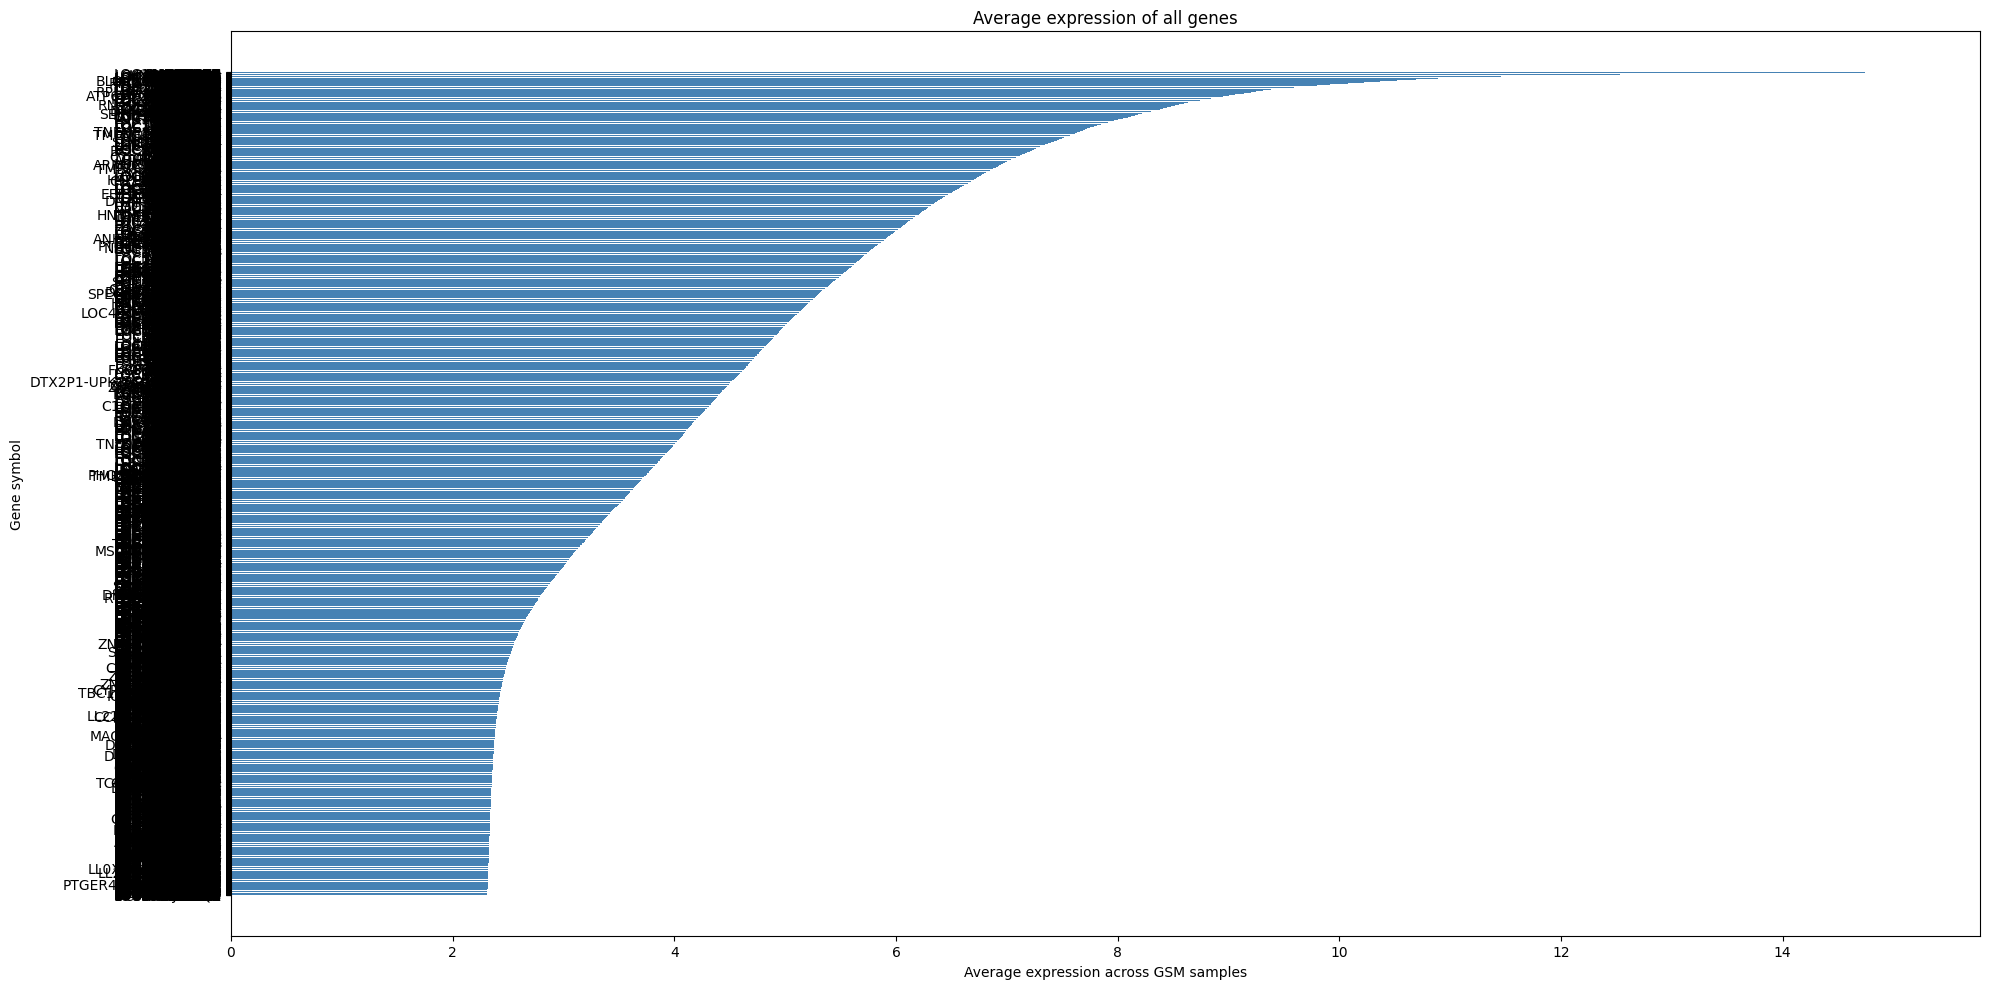

In [25]:
# Average each gene's expression across all GSM samples
gene_means = expression[gsm_columns].mean(axis=1)

# Get the gene symbols and sort by average expression
gene_means.index = expression["Gene_Symbol"]
gene_means = gene_means.sort_values()

plt.figure(figsize=(20, 10))
plt.barh(gene_means.index, gene_means.values, color="steelblue")
plt.xlabel("Average expression across GSM samples")
plt.ylabel("Gene symbol")
plt.title("Average expression of all genes")
plt.tight_layout()
plt.show()

 Top 10 selected genes which have higher average expression in this dataset

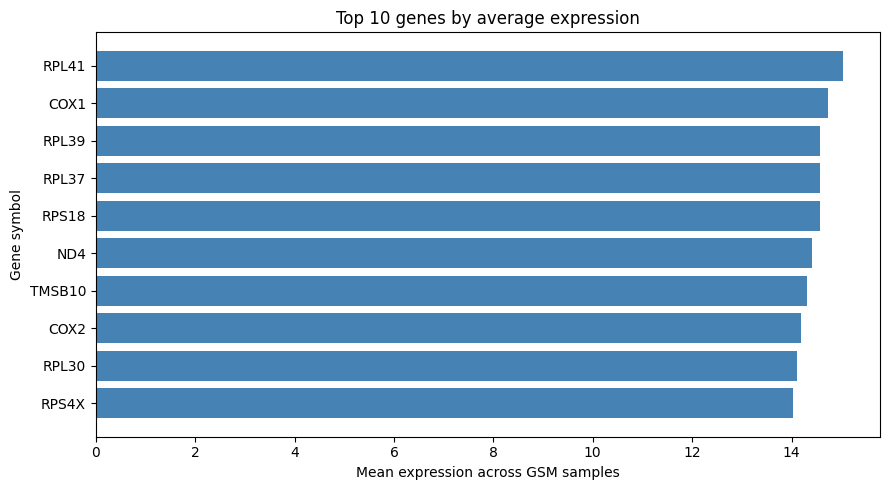

In [27]:
import matplotlib.pyplot as plt

top_10 = gene_summary.nlargest(10, "Mean").sort_values("Mean")

plt.figure(figsize=(9, 5))
plt.barh(top_10["Gene_Symbol"], top_10["Mean"], color="steelblue")
plt.xlabel("Mean expression across GSM samples")
plt.ylabel("Gene symbol")
plt.title("Top 10 genes by average expression")
plt.tight_layout()
plt.show()

Plot 2: Histogram

Expression values concentrated in a particular range

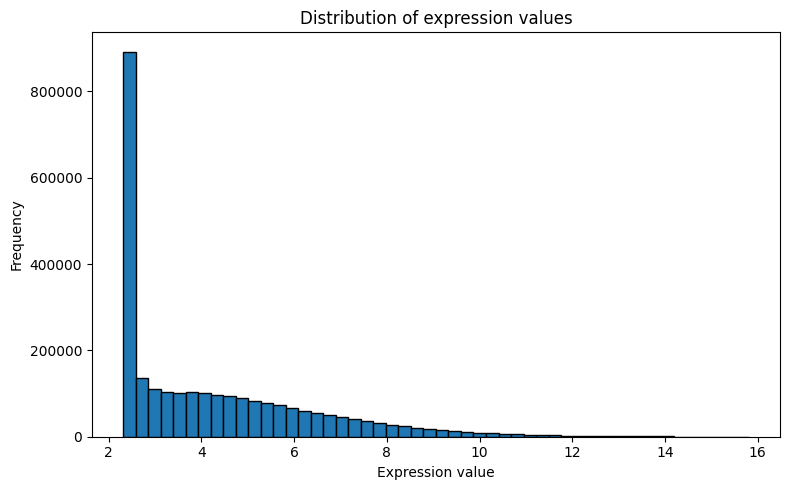

In [29]:
import matplotlib.pyplot as plt
import pandas as pd

gsm_columns = [col for col in expression.columns if col.startswith("GSM")]
values = expression[gsm_columns].apply(pd.to_numeric, errors="coerce").to_numpy().flatten()
values = values[~pd.isna(values)]

plt.figure(figsize=(8, 5))
plt.hist(values, bins=50, edgecolor="black")
plt.xlabel("Expression value")
plt.ylabel("Frequency")
plt.title("Distribution of expression values")
plt.tight_layout()
plt.show()

Plot 3: Box Plot
Compare the distributions of measurements between groups

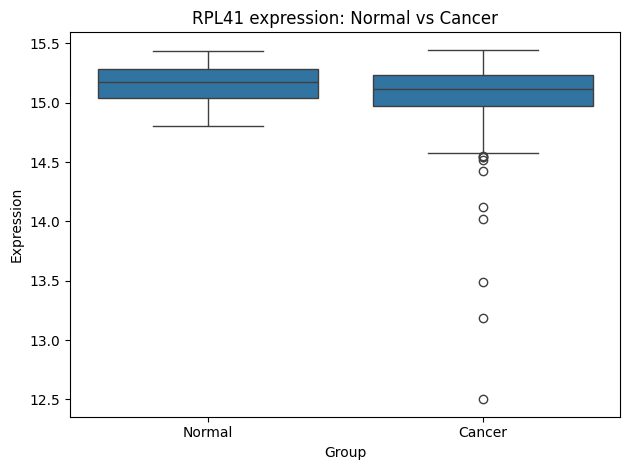

In [30]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

expression = pd.read_csv("GSE42568_gene_symbol_expression_matrix.csv")
metadata = pd.read_csv("GSE42568_sample_metadata.csv")

gene = "RPL41"

# Get this gene's expression value for each GSM sample
gene_row = expression[expression["Gene_Symbol"] == gene].iloc[0]
gene_data = pd.DataFrame({
    "GSM_ID": gene_row.index[1:],
    "Expression": gene_row.iloc[1:].values
})

# Add Normal/Cancer labels to the matching GSM samples
gene_data = gene_data.merge(
    metadata[["Sample", "Condition"]],
    left_on="GSM_ID",
    right_on="Sample"
)

sns.boxplot(data=gene_data, x="Condition", y="Expression",
            order=["Normal", "Cancer"])
plt.title(f"{gene} expression: Normal vs Cancer")
plt.xlabel("Group")
plt.ylabel("Expression")
plt.tight_layout()
plt.show()